In [1]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import matplotlib.patches as ptc
import numpy as np
import os

In [2]:
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = np.array(prop_cycle.by_key()['color'])

os.makedirs("figure1_content", exist_ok=True)

#https://stackoverflow.com/questions/57845444/how-to-convert-a-listedcolormap-to-a-list-of-colors
colors2 = np.array(plt.get_cmap('tab20').colors)
print(colors, colors2)

['#1f77b4' '#ff7f0e' '#2ca02c' '#d62728' '#9467bd' '#8c564b' '#e377c2'
 '#7f7f7f' '#bcbd22' '#17becf'] [[0.12156863 0.46666667 0.70588235]
 [0.68235294 0.78039216 0.90980392]
 [1.         0.49803922 0.05490196]
 [1.         0.73333333 0.47058824]
 [0.17254902 0.62745098 0.17254902]
 [0.59607843 0.8745098  0.54117647]
 [0.83921569 0.15294118 0.15686275]
 [1.         0.59607843 0.58823529]
 [0.58039216 0.40392157 0.74117647]
 [0.77254902 0.69019608 0.83529412]
 [0.54901961 0.3372549  0.29411765]
 [0.76862745 0.61176471 0.58039216]
 [0.89019608 0.46666667 0.76078431]
 [0.96862745 0.71372549 0.82352941]
 [0.49803922 0.49803922 0.49803922]
 [0.78039216 0.78039216 0.78039216]
 [0.7372549  0.74117647 0.13333333]
 [0.85882353 0.85882353 0.55294118]
 [0.09019608 0.74509804 0.81176471]
 [0.61960784 0.85490196 0.89803922]]


0.0 1.0


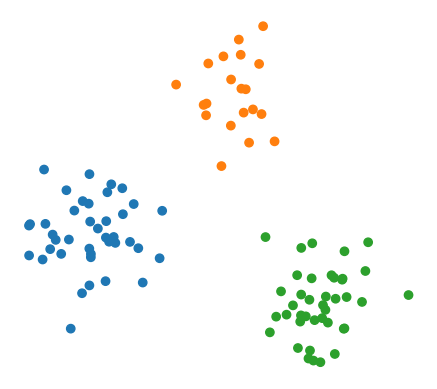

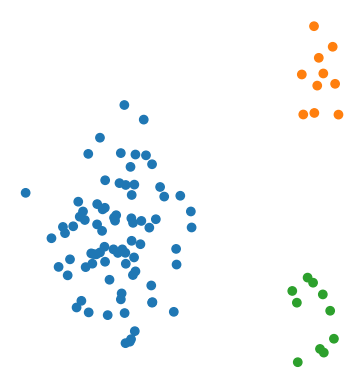

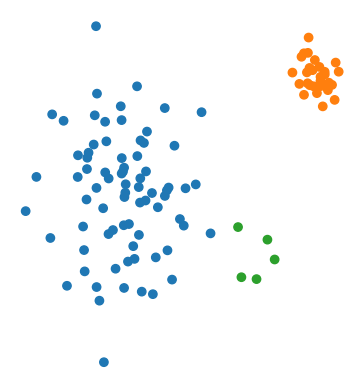

In [3]:
fake_data_X_batch_1, fake_data_y_batch_1 = make_blobs(n_samples=[40, 20, 40], centers=[[8,10], [14,14], [17,8]], random_state=40, shuffle=True, cluster_std=[1.25, 0.9,1])
fake_data_X_batch_2, fake_data_y_batch_2 = make_blobs(n_samples=[80, 10, 10], centers=[[8,10], [16,14], [16,8]], random_state=42, shuffle=True, cluster_std=[1.5, 0.7,1])
fake_data_X_batch_3, fake_data_y_batch_3 = make_blobs(n_samples=[75, 30, 5], centers=[[8,10], [18,14], [15,8]], random_state=44, shuffle=True, cluster_std=[2, 0.5,1])

all_fake_data = np.concatenate([fake_data_X_batch_1, fake_data_X_batch_2, fake_data_X_batch_3])

#print(all_fake_data)
scaler = MinMaxScaler()
scaler.fit(all_fake_data)
all_fake_data_scaled = scaler.transform(all_fake_data)
print(np.min(all_fake_data_scaled), np.max(all_fake_data_scaled))
fake_data_X_batch_1 = scaler.transform(fake_data_X_batch_1)
plt.scatter(fake_data_X_batch_1[:,0], fake_data_X_batch_1[:,1], c=colors[fake_data_y_batch_1])
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/batch_1.svg", bbox_inches='tight')
plt.show()

fake_data_X_batch_2 = scaler.transform(fake_data_X_batch_2)
plt.scatter(fake_data_X_batch_2[:,0], fake_data_X_batch_2[:,1], c=colors[fake_data_y_batch_2])
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/batch_2.svg", bbox_inches='tight')
plt.show()

fake_data_X_batch_3 = scaler.transform(fake_data_X_batch_3)
plt.scatter(fake_data_X_batch_3[:,0], fake_data_X_batch_3[:,1], c=colors[fake_data_y_batch_3])
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/batch_3.svg", bbox_inches='tight')
plt.show()

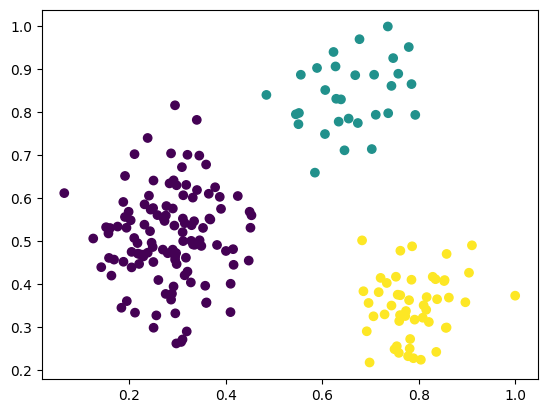

In [4]:
fake_data_actual = np.concatenate([fake_data_X_batch_1, fake_data_X_batch_2])
fake_label_actual = np.concatenate([fake_data_y_batch_1, fake_data_y_batch_2])
plt.scatter(fake_data_actual[:,0], fake_data_actual[:,1], c=fake_label_actual)
#plt.gca().axes.get_yaxis().set_visible(False)
#plt.gca().axes.get_xaxis().set_visible(False)
#ax = plt.gca()
#ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.show()

In [6]:
from summary_handler import process_summary
from online_handler import get_online_method
streamkmeans_config = {"chunk_size": 50, "prototype_num": 10, "k":5}
streamkmeans = get_online_method("streamkmeans_river", streamkmeans_config, 0)
streamkmeans.learn(fake_data_actual, np.arange(len(fake_data_actual)))
streamkmeans_summary = streamkmeans.get_summary()

streamkmeans_assignment, streamkmeans_min_store, streamkmeans_pseudoclustering = process_summary("streamkmeans_river", streamkmeans_summary, fake_data_X_batch_2, 100, True)
streamkmeans_assignment_2, _, _ = process_summary("streamkmeans_river", streamkmeans_summary, fake_data_X_batch_1, 0, True)

print(streamkmeans_min_store)
centers = streamkmeans_min_store["center"]
weights = streamkmeans_min_store["weights"]
radii = streamkmeans_min_store["radii"]
status = streamkmeans_min_store["status"]

print(colors)

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors[streamkmeans_assignment], alpha=0.75)
plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors[streamkmeans_assignment_2], alpha=0.25)

for l in range(len(centers)):
    # print(mc.mean)
    mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4)
    plt.gca().add_patch(mc_patch)
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors[l], marker="X", linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/streamkmeans.svg", bbox_inches='tight')
plt.show()

NotImplementedError: Method streamkm++ is not implemented.

{'id_map': array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), 'center': array([[0.73597818, 1.        ],
       [0.40982537, 0.33560987],
       [0.30771383, 0.74824655],
       [0.74642524, 0.24407452],
       [0.1624614 , 0.5442866 ],
       [0.43596342, 0.49678781],
       [0.72354564, 0.42662169],
       [0.31619909, 0.60263286],
       [0.76571504, 0.88368838],
       [0.27365962, 0.39244173]]), 'radii': array([0.        , 0.        , 0.09480936, 0.07082683, 0.0899003 ,
       0.07095326, 0.08594838, 0.10586646, 0.09493761, 0.12420171]), 'weights': array([ 1.,  1.,  5.,  3.,  8.,  5.,  6., 15.,  4., 33.]), 'status': array(['dense', 'dense', 'dense', 'dense', 'dense', 'dense', 'dense',
       'dense', 'dense', 'dense'], dtype='<U5')}
['#1f77b4' '#ff7f0e' '#2ca02c' '#d62728' '#9467bd' '#8c564b' '#e377c2'
 '#7f7f7f' '#bcbd22' '#17becf']


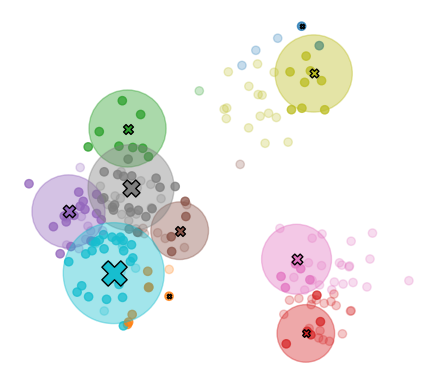

In [19]:
clustream_config = {"mmc": 10, "window": 100, "mu": 2, "beta": 0.6, "epsilon":0.1, "init_num": 100}
method = "clustream_river"
clustream = get_online_method(method, clustream_config, 0)
clustream.learn(fake_data_actual, np.arange(len(fake_data_actual)))
clustream_summary = clustream.get_summary()

clustream_assignment, clustream_min_store, clustream_pseudoclustering = process_summary(method, clustream_summary, fake_data_X_batch_2, 100, True)
clustream_assignment_2, _, _ = process_summary(method, clustream_summary, fake_data_X_batch_1, 0, True)

print(clustream_min_store)
centers = clustream_min_store["center"]
weights = clustream_min_store["weights"]
radii = clustream_min_store["radii"]
status = clustream_min_store["status"]

print(colors)

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors[clustream_assignment], alpha=0.75)
plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors[clustream_assignment_2], alpha=0.25)

for l in range(len(centers)):
    # print(mc.mean)
    mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors[l])
    plt.gca().add_patch(mc_patch)
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors[l], marker="X", linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/{method}.svg", bbox_inches='tight')
plt.show()

36
0.06520983646855011 1.0
{'id_map': array(['4,5', '2,2', '2,3', '1,2', '4,2', '4,1', '3,5', '3,4', '5,2',
       '5,1', '1,3', '1,1', '4,4', '0,3', '3,3', '2,5', '0,2', '4,3',
       '1,4', '2,4', 'deleted'], dtype='<U7'), 'center': array([[0.75      , 0.91666667],
       [0.41666667, 0.41666667],
       [0.41666667, 0.58333333],
       [0.25      , 0.41666667],
       [0.75      , 0.41666667],
       [0.75      , 0.25      ],
       [0.58333333, 0.91666667],
       [0.58333333, 0.75      ],
       [0.91666667, 0.41666667],
       [0.91666667, 0.25      ],
       [0.25      , 0.58333333],
       [0.25      , 0.25      ],
       [0.75      , 0.75      ],
       [0.08333333, 0.58333333],
       [0.58333333, 0.58333333],
       [0.41666667, 0.91666667],
       [0.08333333, 0.41666667],
       [0.75      , 0.58333333],
       [0.25      , 0.75      ],
       [0.41666667, 0.75      ],
       [       inf,        inf]]), 'radii': array([0.08333433, 0.08333433, 0.08333433, 0.08333433, 0.0833

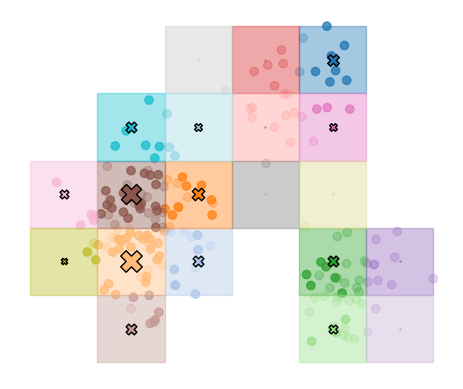

In [20]:
dstream_config = {"dim_grid_num":6, "window": 100}
method = "dstream"
dstream = get_online_method(method, dstream_config, 0)
dstream.learn(fake_data_actual, np.arange(len(fake_data_actual)))
dstream_summary = dstream.get_summary()

print(np.min(fake_data_actual), np.max(fake_data_actual))

dstream_assignment, dstream_min_store, dstream_pseudoclustering = process_summary(method, dstream_summary, fake_data_X_batch_2, 100, True)
dstream_assignment_2, _, dstream_pseudoclustering_2 = process_summary(method, dstream_summary, fake_data_X_batch_1, 0, True)

print(dstream_min_store)
centers = dstream_min_store["center"][:-1]
weights = dstream_min_store["weights"][:-1]
radii = dstream_min_store["radii"][:-1]
status = dstream_min_store["status"][:-1]

print(len(centers))

print(colors)

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors2[dstream_assignment%20], alpha=0.75)
plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors2[dstream_assignment_2%20], alpha=0.25)

for l in range(len(centers)):
    # print(mc.mean)
    mc_patch = ptc.Rectangle((centers[l]-radii[l]), 2*radii[l], 2*radii[l], alpha=0.4, color=colors2[l%20])
    plt.gca().add_patch(mc_patch)

    if status[l] == "dense":
        marker = "X"
    else:
        marker = "."
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors2[l%20], marker=marker, linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/{method}.svg", bbox_inches='tight')
plt.show()

['#1f77b4' '#ff7f0e' '#2ca02c' '#d62728' '#9467bd' '#8c564b' '#e377c2'
 '#7f7f7f' '#bcbd22' '#17becf']


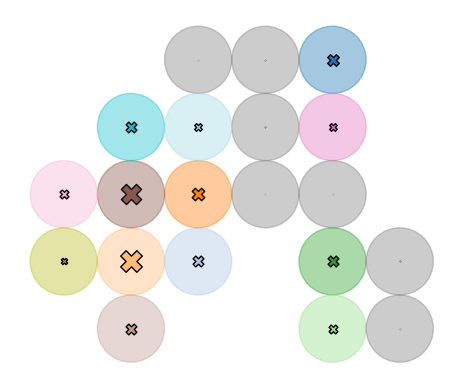

In [21]:
centers = dstream_min_store["center"][:-1]
weights = dstream_min_store["weights"][:-1]
radii = dstream_min_store["radii"][:-1]
status = dstream_min_store["status"][:-1]

print(colors)

#plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors2[dstream_assignment], alpha=0.25)
#plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors2[dstream_assignment_2], alpha=0.05)

for l in range(len(centers)):
    # print(mc.mean)
    if status[l] == "dense":
        mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors2[l])
    else:
        mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color="#808080")

    if status[l] == "dense":
        marker = "X"
    else:
        marker = "."
    plt.gca().add_patch(mc_patch)
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors2[l], marker=marker, linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/mini_summary_{method}.svg", bbox_inches='tight')
plt.show()

In [22]:
import utils
positions = dstream_min_store["center"]
weights = dstream_min_store["weights"]
radii = dstream_min_store["radii"]
status = dstream_min_store["status"]
mc_dists = utils.distance_calc(positions, positions, dist="euclidean")
two_radii = np.array([radii + radii[i] for i in range(len(positions))])
connected = np.where(mc_dists <= two_radii, True, False)
partitions = np.arange(len(positions)+1)  # get connected
for i in range(len(partitions)-1):
    if status[i] != "outlie" and status[i] != "sporadic" and status[i] != "delete":
        for j in range(i):
            if status[j] != "outlie" and status[j] != "sporadic" and status[j] != "delete":
                if connected[i, j]:
                    if partitions[i] != partitions[j]:
                        if status[i] == "dense" and status[j] == "dense":
                            key = min(partitions[i], partitions[j])
                            other_key = max(partitions[i], partitions[j])
                            partitions[np.where(partitions == other_key)[0]] = key
                        elif status[i] == "normal" and status[j] == "dense":
                            partitions[i] = partitions[j]
                        elif status[i] == "dense" and status[j] == "normal":
                            partitions[j] = partitions[i]
    else:
        partitions[i] = -1
partitions[-1] = -1
print(partitions, len(partitions))
print(status, len(status))

[ 0  1  1  1  4  4 -1 -1 -1 -1  1  1  0  1 -1 -1  1 -1  1  1 -1 -1] 22
['dense' 'dense' 'dense' 'dense' 'dense' 'dense' 'outlie' 'outlie'
 'outlie' 'outlie' 'dense' 'dense' 'dense' 'dense' 'outlie' 'outlie'
 'dense' 'outlie' 'dense' 'dense' 'delete'] 21


['#1f77b4' '#ff7f0e' '#2ca02c' '#d62728' '#9467bd' '#8c564b' '#e377c2'
 '#7f7f7f' '#bcbd22' '#17becf']
[4 1 1 1 0 1 1 1 1 1 1 0 1 4 0 0 1 1 0 1 1 1 4 1 0 1 1 1 4 1 1 1 1 4 1 1 4
 1 1 0 1 1 1 1 1 0 1 1 4 1 1 1 1 4 1 4 1 1 1 4 1 1 1 1 1 1 1 1 1 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1]
[ 0  1  1  1  1  1  4  1  4  4  4  4  4 -1 -1  1 -1  4 -1 -1  4 -1  1 -1
 -1  1  1 -1  0  1  4 -1  1 -1  1  4  1  1  4  1  4  1 -1  1 -1  4 -1 -1
  1  4  4 -1  1 -1 -1  1  4 -1  1  1 -1 -1  4  1  4  1  0  1  4  4  1  4
  1 -1  1  4 -1  1  4 -1  1  0  4  1 -1  1 -1  1 -1  1  1 -1  1  1  4 -1
 -1  1  1  4]


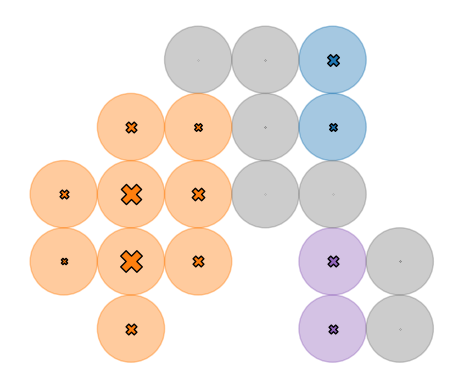

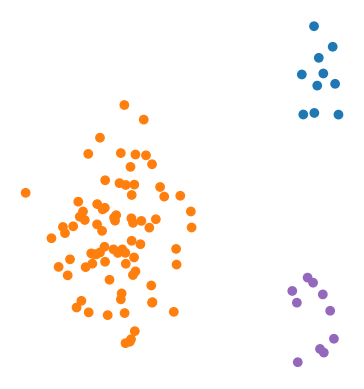

In [23]:
import copy

centers = dstream_min_store["center"][:-1]
weights = dstream_min_store["weights"][:-1]
radii = dstream_min_store["radii"][:-1]
status = dstream_min_store["status"][:-1]

print(colors)
colors_noise = colors.tolist()
colors_noise.append("#808080")
colors_noise = np.array(colors_noise)


print(dstream_pseudoclustering)
print(dstream_pseudoclustering_2)

#plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_pseudoclustering], alpha=0.25)
#plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors_noise[dstream_pseudoclustering_2], alpha=0.05)

for l in range(len(centers)):
    # print(mc.mean)
    mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[partitions[l]])
    plt.gca().add_patch(mc_patch)
    if partitions[l] == -1:
        plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[partitions[l]], marker=".", linewidths=1, edgecolors="black")
    else:
        plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[partitions[l]], marker="X", linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/adjacency_{method}.svg", bbox_inches='tight')
plt.show()


# for l in range(len(centers)):
#     # print(mc.mean)
#     mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[partitions[l]])
#     plt.gca().add_patch(mc_patch)
#     plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[partitions[l]], marker="X", linewidths=1, edgecolors="black")

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_pseudoclustering], alpha=1)

plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/adjacency_{method}_clustering.svg", bbox_inches='tight')
plt.show()

[[0.75       0.91666667]
 [0.41666667 0.41666667]
 [0.41666667 0.58333333]
 [0.25       0.41666667]
 [0.75       0.41666667]
 [0.75       0.25      ]
 [0.58333333 0.91666667]
 [0.58333333 0.75      ]
 [0.91666667 0.41666667]
 [0.91666667 0.25      ]
 [0.25       0.58333333]
 [0.25       0.25      ]
 [0.75       0.75      ]
 [0.08333333 0.58333333]
 [0.58333333 0.58333333]
 [0.41666667 0.91666667]
 [0.08333333 0.41666667]
 [0.75       0.58333333]
 [0.25       0.75      ]
 [0.41666667 0.75      ]]
[7.0040e+00 6.0120e+00 8.0120e+00 2.4022e+01 6.0240e+00 4.0280e+00
 1.0000e-02 1.8000e-02 2.0000e-02 6.0000e-03 2.1026e+01 6.0020e+00
 3.0040e+00 4.0040e+00 2.0000e-03 2.0000e-03 2.0020e+00 2.0000e-03
 6.0000e+00 3.0000e+00]
[0 1 1 1 2 1 1 1 1 1 1 2 1 0 2 2 1 1 2 1 1 1 0 1 2 1 1 1 0 1 1 1 1 0 1 1 0
 1 1 2 1 1 1 1 1 2 1 1 0 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 2 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1]
[ 2  1  1  1  1  1  0  1  0  0  0  0  0 -1 -1  1 -1  0 -1 -1  0 -1  1 

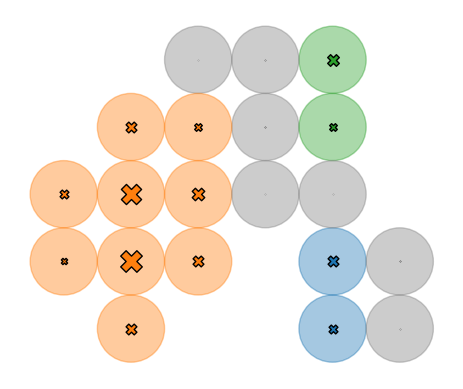

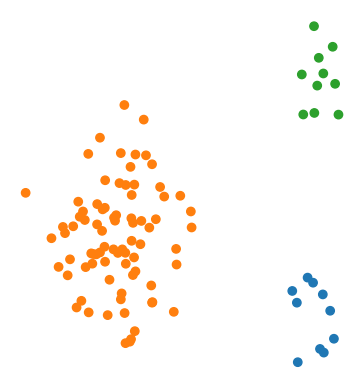

In [24]:
from offline_handler import get_summary_clustering, get_offline_clustering

centers = dstream_min_store["center"][:-1]
weights = dstream_min_store["weights"][:-1]
radii = dstream_min_store["radii"][:-1]
status = dstream_min_store["status"][:-1]

print(centers)
print(weights)
colors_noise = colors.tolist()
colors_noise.append("#808080")
colors_noise = np.array(colors_noise)



kmeans_config = {"n_clusters":3}
dstream_kmeans_clustering = get_summary_clustering(centers, weights, "kmeans", kmeans_config, 0)
for l in range(len(centers)):
    if status[l] != "dense":
        dstream_kmeans_clustering[l] = -1

dstream_kmeans_data_clustering = get_offline_clustering(dstream_assignment, dstream_kmeans_clustering)
dstream_kmeans_data_clustering_2 = get_offline_clustering(dstream_assignment_2, dstream_kmeans_clustering)


print(dstream_kmeans_data_clustering)
print(dstream_kmeans_data_clustering_2)

#plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_kmeans_data_clustering], alpha=0.25)
#plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors_noise[dstream_kmeans_data_clustering_2], alpha=0.05)

for l in range(len(centers)):
    # print(mc.mean)
    if status[l] == "dense":
        mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[dstream_kmeans_clustering[l]])
        marker = "X"
    else:
        mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color="#808080")
        marker = "."
    plt.gca().add_patch(mc_patch)
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[dstream_kmeans_clustering[l]], marker=marker, linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/kmeans_{method}.svg", bbox_inches='tight')
plt.show()


# for l in range(len(centers)):
#     # print(mc.mean)
#     mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[partitions[l]])
#     plt.gca().add_patch(mc_patch)
#     plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[partitions[l]], marker="X", linewidths=1, edgecolors="black")

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_kmeans_data_clustering], alpha=1)

plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/kmeans_{method}_clustering.svg", bbox_inches='tight')
plt.show()

[[0.75       0.91666667]
 [0.41666667 0.41666667]
 [0.41666667 0.58333333]
 [0.25       0.41666667]
 [0.75       0.41666667]
 [0.75       0.25      ]
 [0.58333333 0.91666667]
 [0.58333333 0.75      ]
 [0.91666667 0.41666667]
 [0.91666667 0.25      ]
 [0.25       0.58333333]
 [0.25       0.25      ]
 [0.75       0.75      ]
 [0.08333333 0.58333333]
 [0.58333333 0.58333333]
 [0.41666667 0.91666667]
 [0.08333333 0.41666667]
 [0.75       0.58333333]
 [0.25       0.75      ]
 [0.41666667 0.75      ]]
[7.0040e+00 6.0120e+00 8.0120e+00 2.4022e+01 6.0240e+00 4.0280e+00
 1.0000e-02 1.8000e-02 2.0000e-02 6.0000e-03 2.1026e+01 6.0020e+00
 3.0040e+00 4.0040e+00 2.0000e-03 2.0000e-03 2.0020e+00 2.0000e-03
 6.0000e+00 3.0000e+00]
[-1  0  0  0 -1  0  0  0  0  0  0 -1  0 -1 -1 -1  0  0 -1  0  0  0 -1  0
 -1  0  0  0 -1  0  0  0  0 -1  0  0 -1  0  0 -1  0  0  0  0  0 -1  0  0
 -1  0  0  0  0 -1  0 -1  0  0  0 -1  0  0  0  0  0  0  0  0  0 -1  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 

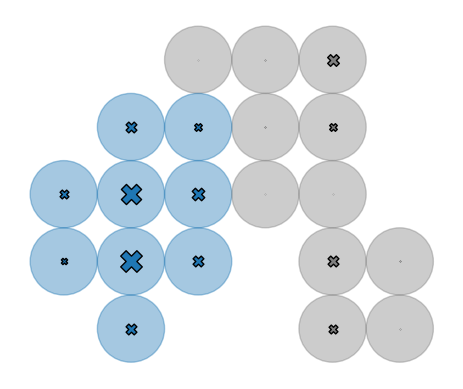

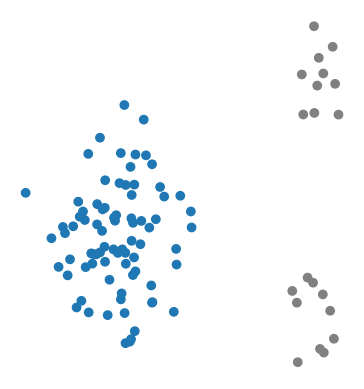

In [25]:
from offline_handler import get_summary_clustering, get_offline_clustering

centers = dstream_min_store["center"][:-1]
weights = dstream_min_store["weights"][:-1]
radii = dstream_min_store["radii"][:-1]
status = dstream_min_store["status"][:-1]

print(centers)
print(weights)
colors_noise = colors.tolist()
colors_noise.append("#808080")
colors_noise = np.array(colors_noise)



dbscan_config = {"eps": 0.17, "min_samples": 11}
dstream_dbscan_clustering = get_summary_clustering(centers, weights, "dbscan", dbscan_config, 0)

for l in range(len(centers)):
    if status[l] != "dense":
        dstream_dbscan_clustering[l] = -1

dstream_dbscan_data_clustering = get_offline_clustering(dstream_assignment, dstream_dbscan_clustering)
dstream_dbscan_data_clustering_2 = get_offline_clustering(dstream_assignment_2, dstream_dbscan_clustering)


print(dstream_dbscan_data_clustering)
print(dstream_dbscan_data_clustering_2)

#plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_dbscan_data_clustering], alpha=0.25)
#plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors_noise[dstream_dbscan_data_clustering_2], alpha=0.05)

for l in range(len(centers)):
    # print(mc.mean)
    mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[dstream_dbscan_clustering[l]])
    plt.gca().add_patch(mc_patch)
    if status[l] == "dense":
        marker = "X"
    else:
        marker = "."
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[dstream_dbscan_clustering[l]], marker=marker, linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/dbscan_{method}.svg", bbox_inches='tight')
plt.show()


# for l in range(len(centers)):
#     # print(mc.mean)
#     mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[partitions[l]])
#     plt.gca().add_patch(mc_patch)
#     plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[partitions[l]], marker="X", linewidths=1, edgecolors="black")

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_dbscan_data_clustering], alpha=1)

plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/dbscan_{method}_clustering.svg", bbox_inches='tight')
plt.show()

[[0.75       0.91666667]
 [0.41666667 0.41666667]
 [0.41666667 0.58333333]
 [0.25       0.41666667]
 [0.75       0.41666667]
 [0.75       0.25      ]
 [0.58333333 0.91666667]
 [0.58333333 0.75      ]
 [0.91666667 0.41666667]
 [0.91666667 0.25      ]
 [0.25       0.58333333]
 [0.25       0.25      ]
 [0.75       0.75      ]
 [0.08333333 0.58333333]
 [0.58333333 0.58333333]
 [0.41666667 0.91666667]
 [0.08333333 0.41666667]
 [0.75       0.58333333]
 [0.25       0.75      ]
 [0.41666667 0.75      ]]
[7.0040e+00 6.0120e+00 8.0120e+00 2.4022e+01 6.0240e+00 4.0280e+00
 1.0000e-02 1.8000e-02 2.0000e-02 6.0000e-03 2.1026e+01 6.0020e+00
 3.0040e+00 4.0040e+00 2.0000e-03 2.0000e-03 2.0020e+00 2.0000e-03
 6.0000e+00 3.0000e+00]
0.0 1.002 0.8975274678557505
{'metric': 'euclidean', 'distance_threshold': 0.2, 'gaussian': True, 'min_rho': np.float64(1.002), 'min_delta': 0.2, 'hard_assign': False, 'halo': True, 'halo_avg': True, 'halo_noise': True, 'allow_duplicate': True}
[ 1  2  2  2  0  2  2  2  2  

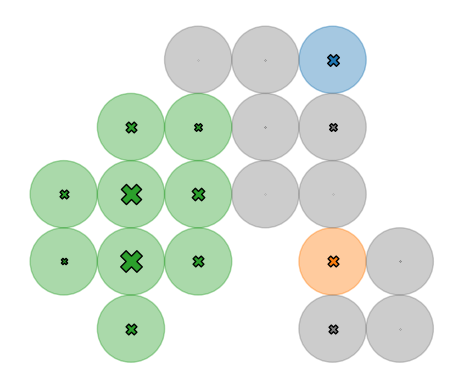

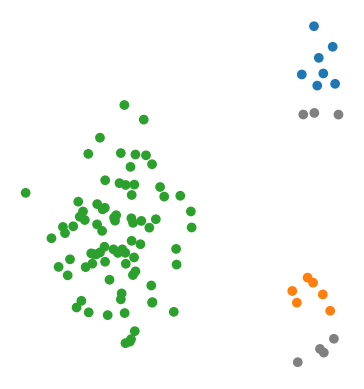

In [26]:
from offline_config_handler import estimate_defaults_dpc
from offline_handler import get_summary_clustering, get_offline_clustering

centers = dstream_min_store["center"][:-1]
weights = dstream_min_store["weights"][:-1]
radii = dstream_min_store["radii"][:-1]
status = dstream_min_store["status"][:-1]

print(centers)
print(weights)
colors_noise = colors.tolist()
colors_noise.append("#808080")
colors_noise = np.array(colors_noise)


distance_threshold, min_rho, max_distance = estimate_defaults_dpc(centers, weights, default_ratio=0.01, dist_metric="euclidean")
print(distance_threshold, min_rho, max_distance)
dpc_config = {"distance_threshold": 0.2, "min_rho": min_rho, "min_delta": 0.2,
              "hard_assign": False, "halo": True, "halo_avg": True, "allow_duplicate": True, "gaussian": True
              }


dstream_dpc_clustering = get_summary_clustering(centers, weights, "dpc", dpc_config, 0).astype("int")

for l in range(len(centers)):
    if status[l] != "dense":
        dstream_dpc_clustering[l] = -1


dstream_dpc_data_clustering = get_offline_clustering(dstream_assignment, dstream_dpc_clustering)
dstream_dpc_data_clustering_2 = get_offline_clustering(dstream_assignment_2, dstream_dpc_clustering)


print(dstream_dpc_data_clustering)
print(dstream_dpc_data_clustering_2)

#plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_dpc_data_clustering], alpha=0.25)
#plt.scatter(x=fake_data_X_batch_1[:, 0], y=fake_data_X_batch_1[:, 1], c=colors_noise[dstream_dpc_data_clustering_2], alpha=0.05)

for l in range(len(centers)):
    # print(mc.mean)
    mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[dstream_dpc_clustering[l]])
    plt.gca().add_patch(mc_patch)
    if status[l] == "dense":
        marker = "X"
    else:
        marker = "."
    plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[dstream_dpc_clustering[l]], marker=marker, linewidths=1, edgecolors="black")
plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/dpc_{method}.svg", bbox_inches='tight')
plt.show()


# for l in range(len(centers)):
#     # print(mc.mean)
#     mc_patch = ptc.Circle((float(centers[l][0]), float(centers[l][1])), radii[l], alpha=0.4, color=colors_noise[partitions[l]])
#     plt.gca().add_patch(mc_patch)
#     plt.scatter(x=centers[l][0], y=centers[l][1], alpha=1, s=weights[l] * 10, c=colors_noise[partitions[l]], marker="X", linewidths=1, edgecolors="black")

plt.scatter(x=fake_data_X_batch_2[:, 0], y=fake_data_X_batch_2[:, 1], c=colors_noise[dstream_dpc_data_clustering], alpha=1)

plt.gca().axes.get_yaxis().set_visible(False)
plt.gca().axes.get_xaxis().set_visible(False)
ax = plt.gca()
ax.axis('off')
ax.set_aspect('equal', adjustable='box')
plt.savefig(f"figure1_content/dpc_{method}_clustering.svg", bbox_inches='tight')
plt.show()